# Results {#sec-results}

In this section, we show how we obtain our results. The figures shown here are the main and supplementary figures in our article. The key results can be summarized as follows:
* The influence of optimism on performance in a two-armed bandit task is modulated by resource scarcity
* Optimism increases risk-seeking in a risk-reward dilemma
* Optimism enhances cooperation in a stag-hunt game
* Optimism/pessimism has no effect on cooperation in a prisoner's dilemma

First, we import what we need.

In [1]:
# general imports

import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

import matplotlib.pyplot as plt
import matplotlib as mpl

import pandas as pd
import seaborn as sns

In [2]:
# pyCRLD imports

# Agents
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA
from pyCRLD.Agents.StrategyActorCritic import stratAC

# Environments
from pyDDRL.Environments.SocialDilemma import SocialDilemma
from pyDDRL.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyDDRL.Environments.TwoArmedBandit import TwoArmedBandit

# Utilities
from pyCRLD.Utils.Helpers import *
from pyDDRL.Utils.Trajectories1D import trajectories_1D 
from pyDDRL.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
from pyCRLD.Utils import FlowPlot as fp

In [3]:
# DDRL imports

from pyDDRL.Agents.DDRLBase import DDRLBase
from pyDDRL.Agents.DDRLSarsa import DDRLSarsa
from pyDDRL.Agents.DDRLActorCritic import DDRLActorCritic

## The influence of optimism on performance in a two-armed bandit task is modulated by resource scarcity

We want to study the effect of optimism/pessimism in a two-armed bandit task. To do so, we define functions that help us visualize 
* the phase plots for varying levels of optimism/pessimism
* the deterministic strategies over time for varying levels of optimism/pessimism
* the average payoff collected over time for varying levels of optimism/pessimism.

In [57]:
## Functions to generate phase plots + trajs + mean rewards

# Obtain dX as a function of X for phase plots
# Also works when N=2 or Z=2
def obtain_dXs(aei,  # agent-environment interface
               res,  # range & resolution of strategies
               xinds:tuple,  # of indices of the phase space object to plot along the x axis
               traj_len:int,  # trajectory len
               otherXs=None,  # when N=2 or Z=2: values of X in 2nd condition
               ):
        
    l = len(res)
    dXs = np.zeros((aei.Z, l))  # will store the dXs

    for i in range(aei.Z):
        
        for j, xval in enumerate(res):  # loop over Xs
            
            if (aei.N > 1) or (aei.Z > 1): # 2 states or 2 actions
                xval_ = otherXs[j]
            else:
                xval_ = None
                
            X = obtain_Xs(aei, xinds, xval, xval_)  # create X with values along all dims
            prederror = aei.TDerror(X, norm=True)  # compute pred error
            dX = aei.step(X)[0] - X  # compute dX
            dXs[i, j] = dX[xinds[0], i, xinds[2]][0]  # dX for i,s,a of interest
            
    return dXs


def obtain_Xs(aei,  # CRLD multi-agent environment object
              xinds:tuple,  # of indices of the phase space item to plot along the x axis
              xval:float,  # the value of the phase space item to plot along the x axis
              xval_:float  # the value of X in the 2nd condition
              ): 
    
    N, C, M = aei.N, aei.Z, aei.M  # Number of agents, states, actions
    
    Xs = np.zeros((N, C, M))  # will store the Xs
    
    xi, xc, xa = xinds  # plotted agent, state, action
    xa_ = tuple(set(range(M)) - set(xa))  # other action
    
    Xs[xi, xc, xa] = xval  # setting x value
    
    # probability of taking other action
    Xs[xi,xc,xa_] = 1-Xs[xi, xc, xa]
    
    if C > 1:  # more than one state
        xc_ = tuple(set(range(C)) - set(xc))  # other state
        Xs[xi, xc_, xa] = xval_  # strategy in state 2 for action 1
        Xs[xi, xc_, xa_] = 1 - Xs[xi, xc_, xa]  # strategy in state 2 for action 2
    if N > 1:  # more than 1 agent
        xi_ = tuple(set(range(N)) - set(xi))  # other agent
        Xs[xi_, xc, xa] = xval_  # other agent's strategy for action 1
        Xs[xi_, xc, xa_] = 1 - Xs[xi_, xc, xa]  # other agent's strat for action 2
    
    return Xs

# Compute X traj and reward traj
def reward_traj(aei,  # CRLD multi-agent environment object
                X:tuple,  # strategy
                i,  # agent
                traj_len:int=500,  # trajectory length
                ): 
    
    r_traj = np.zeros((traj_len))  # will store rewards
    # Compute X trajectory
    traj, fpreached = aei.trajectory(X, traj_len) 
    # Compute reward trajectory
    for t in range(traj_len):
        r_traj[t] = aei.Ri(traj[t,...])[i]
        
    return traj, r_traj
    
# Plot phase plot, X traj and reward traj for various levels of optimism/pessimism
def compare_levels(env,  # environment
                   level_list,  # list of levels
                   gamma,  # discount factor
                   beta,  # choice intensity
                   Rmin,  # min reward perceived
                   Rmax,  # max reward perceived
                   xinds:tuple,  # which phase space axes to plot along x axes
                   res,  # specify range & resolution
                   algo='SARSA',  # specify algorithm
                   nrb:int=29,  # number of neurons
                   discsig:float=0.05,  # discretization sigma
                   lr:float=0.1,  # learning rate
                   traj_len:int=500,  # trajectory length
                   otherXs=None,  # if 2nd condition: values of X along this condition
                   cmap='viridis',  # colormap
                   save=False,  # save fig?
                   savename=None,  # saved figure's name
                   axes=None,  # Axes to plot into
                   ):  
   

    # Fig and Axes
    # Style
    sns.set_style("whitegrid")
    sns.set_context("paper", font_scale=1.5, rc={"lines.linewidth": 2})
    
    # Subplots: phase plot, X traj, reward traj
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(4.5 * 3.8, 3.8))
    
    # Colormap for the different lines
    cmap = mpl.colormaps[cmap]
    ext = np.linspace(0, 1, len(level_list))  # extent of colormap
    colors = cmap(tuple(ext))
    # Neutral agent is represented with a black line
    colors[int(len(level_list)/2)] = [0, 0, 0, 1]  
    
    # Zero line
    zero = np.zeros((len(res))) 

    # Loop over optimism/pessimism levels
    for j, level in enumerate(level_list):
        
        # Define agent-environment interface
        if algo=='SARSA':
            aei = DDRLSarsa(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                            learning_rates=lr, discount_factors=gamma, 
                            choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                            method="weights", wU=level, use_prefactor=True)
        elif algo=='AC':
            aei = DDRLActorCritic(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                                  learning_rates=lr, discount_factors=gamma, 
                                  Rmin=Rmin, Rmax=Rmax,
                                  method="weights", wU=level, use_prefactor=True)
 
        # Obtain the dXs for y-axis of phase plot
        dXs = obtain_dXs(aei, res, xinds, traj_len, otherXs)
        
        # Phase plot
        ax1.plot(res, dXs[0, :], color=colors[j])
        ax1.plot(res, zero, color="grey", ls='dashed')  # plot zero line
        
        # Obtain X traj and reward traj
        X0 = np.ones((aei.N, aei.Z, aei.M)) * 0.5  # init random strategy
        X_traj, r_traj = reward_traj(aei, X0, 0, traj_len=traj_len)
        
        # X traj plot
        ax2.plot(np.arange(0, traj_len), X_traj[:,0,0,0], 
                 color=colors[j], label=r'$w_{U}=$'+str(level))
        
        # Reward plot
        ax3.plot(np.arange(0, traj_len), r_traj, 
                 color=colors[j], label=r'$w_{U}=$'+str(level))
        
    # Decorations
    ax1.set_ylabel(r"$dX$")
    ax1.set_xlabel("strategy "+r'$X$')
    ax1.set_title('phase plot')
    ax2.set_xlabel("time step "+r'$t$')
    ax2.set_ylabel("strategy "+r'$X^{0,0,0}(t)$')
    ax2.set_title('strategy over time')
    ax3.set_xlabel("time step "+r'$t$')
    ax3.set_ylabel("reward "+r'$R^{0}(t)$')
    ax3.set_title('mean reward over time')
    ax3.legend(bbox_to_anchor=(1.01, 1.01), title='weights '+r'$w_U$')
    fig.tight_layout()
    
    # Save figure
    if save == True:
        plt.savefig(savename, dpi=300, bbox_inches='tight')

### Influence of optimism/pessimism on performance in a poor environment

In a "poor" two-armed bandit task, rewards are scarce. We thus define a two-armed bandit task with $p_1 = 0.3$, and $p_2 = 0.1$.

In [17]:
# Poor environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

Now, we can plot the phase plot, strategy over time, and reward over time, of an agent which performs this task. We compare several levels of optimism and pessimism. These levels are defined by the upper weights $w_U$ - that is, the weights the agent applies to the upper part of the distribution.

In [18]:
# List of weight values to compare
weights = np.array([0.1, 0.2, 0.4, 0.8, 1., 2., 4., 8., 10.])

# i,s,a to plot along the x-axis
x = ([0], [0], [0]) 

# Range and resolution of X
res = np.linspace(0, 1., 21) 
res[0] = 0.0001
res[-1] = 0.9999

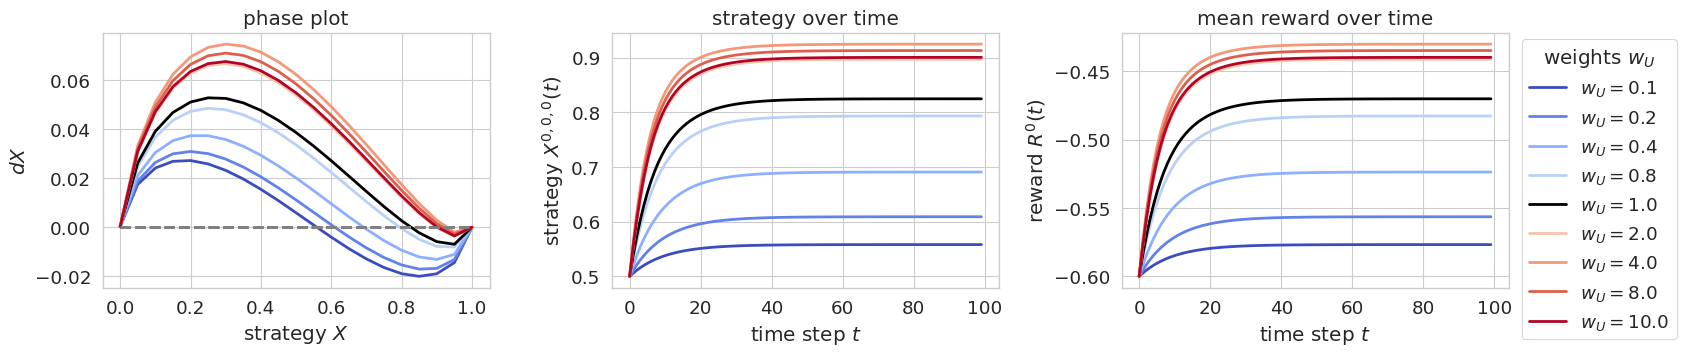

In [19]:
compare_levels(env, weights, gamma=0., beta=4., Rmin=-1, Rmax=1, 
               xinds=x, res=res, nrb=29, discsig=0.05, traj_len=100, 
               cmap='coolwarm', save=False, 
               savename='_figs_v2/TwoArmedPoorPhasePlot.png')

### Influence of optimism/pessimism on performance in a rich environment

In a "rich" two-armed bandit task, rewards are abundant. We thus define a two-armed bandit task with $p_1 = 0.9$, and $p_2 = 0.7$.

In [21]:
# Rich environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.1, 0.9],
               [0.3, 0.7]])
env = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

Now, we can plot the phase plot, strategy over time, and reward over time, of an agent performing the rich task. We compare the same levels of optimism and pessimism as above.

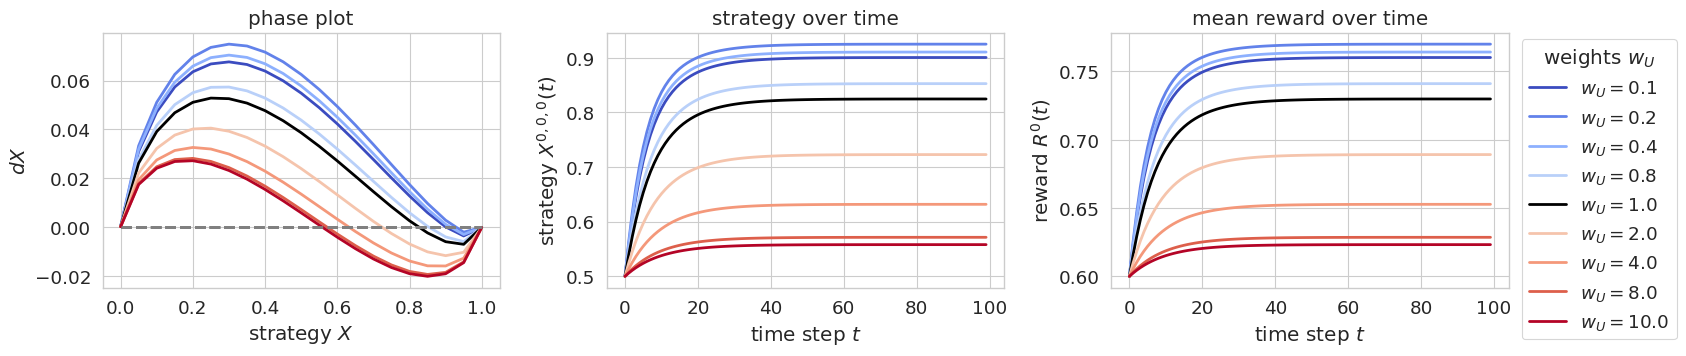

In [22]:
compare_levels(env, weights, gamma=0., beta=4., Rmin=-1, Rmax=1, 
               xinds=x, res=res, nrb=29, discsig=0.05, traj_len=100, 
               cmap='coolwarm', save=False, 
               savename='_figs_v2/TwoArmedRichPhasePlot.png')

### Comparison between the three DDRL biasing methods and asymmetric RL

Asymmetric RL was previously used to model optimism and pessimism in simple RL algorithms. It postulates a pair of asymmetric learning rates: a learning rate $\alpha^{+}$ that updates positive prediction errors, and a rate $\alpha^{-}$ that updates negative prediction errors. The bias strength $b$ is defined by the learning-rates ratio: 

$$ b = \frac{\alpha^{+}}{\alpha^{-}} $$

Cazé and Van der Meer (2013) have shown that, for an agent with bias strength $b$, the Q-value at steady-state of arm $a_{i}$ is:

$$ Q^{a_i}_{\infty} = \frac{p_{a_i} \cdot b - (1 - p_{a_i})}{p_{a_i} \cdot b + (1 - p_{a_i})} $$

Below, we compare the final strategies obtained with the three DDRL biasing methods (quantile, expectile, weights) against the final strategies obtained with asymmetric RL.

First, we define functions that will help us visualize these comparisons.

In [23]:
## Functions for comparisons between DDRL biasing methods and asymmetric RL

# Compute Q-value gap at steady state
def deltaQinf(p0,  # reward prob of arm 1 
              p1,  # reward prob of arm 2
              b):  # bias strength
    return ((p0 * b - (1 - p0)) / (p0 * b + (1 - p0))) - ((p1 * b - (1 - p1)) / (p1 * b + (1 - p1)))

# Compute prob of choosing most rewarding arm at steady state
def Xinf(dQ,  # Q-value gap
         beta):  # choice intensity
    return 1 / (1 + np.exp(beta * (-dQ)))

# Compute final strategies for quantile, expectile, weights, and asymRL methods
def compute_comparisons(p0,  # reward prob of arm 1
                        p1,  # reward prob of arm 2
                        b_ratios,  # bias strengths for asymRL
                        q_list,  # quantiles
                        e_list,  # expectiles
                        w_list,  # weights
                        gamma,  # discount factor
                        beta,  # choice intensity
                        Rmin,  # min reward perceived
                        Rmax,  # max reward perceived
                        nrb:int=29,  # number of neurons
                        discsig:float=0.05,  # discretization sigma
                        lr:float=0.1,  # learning rate
                        axes=None,  # axes to plot into
                        ):
    
    # Create 2-armed bandit
    xs = np.array([[-1, 1],
                   [-1, 1]])
    ps = np.array([[1-p0, p0],
                   [1-p1, p1]])
    env = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)
    
    # Compute asymRL Xinf for each bias strength
    b_dQs = deltaQinf(p0, p1, b_ratios)  # Q-value gaps
    b_xinf = Xinf(b_dQs, beta)  # final strategies
    
    # Compute quantile Xinf for each quantile
    q_xinf = np.zeros((len(q_list)))
    for i, q in enumerate(q_list):
        # Define agent-env interface
        aei = DDRLSarsa(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                        learning_rates=lr, discount_factors=gamma,
                        choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                        method='quantile', tau=q, use_prefactor=False)
        # Initial strategy
        X = 0.5 * np.ones((aei.N, aei.Z, aei.M))
        # Compute strategy trajectory
        traj, fpreached = aei.trajectory(X, 150)
        # Take the last X^{0,0,0} of the trajectory
        q_xinf[i] = traj[-1, 0, 0, 0]
        
    # Compute expectile Xinf for each expectile
    e_xinf = np.zeros((len(e_list)))
    for i, e in enumerate(e_list):
        # Define agent-env interface
        aei = DDRLSarsa(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                        learning_rates=lr, discount_factors=gamma,
                        choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                        method='expectile', tau=e, use_prefactor=False)
        # Initial strategy
        X = 0.5 * np.ones((aei.N, aei.Z, aei.M))
        # Compute strategy trajectory
        traj, fpreached = aei.trajectory(X, 150)
        # Take the last X^{0,0,0} of the trajectory
        e_xinf[i] = traj[-1, 0, 0, 0]
        
    # Compute weights Xinf for each upper weight value
    w_xinf = np.zeros((len(w_list)))
    for i, w in enumerate(w_list):
        # Define agent-env interface
        aei = DDRLSarsa(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                        learning_rates=lr, discount_factors=gamma,
                        choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                        method='weights', wU=w, use_prefactor=False)
        # Initial strategy
        X = 0.5 * np.ones((aei.N, aei.Z, aei.M))
        # Compute strategy trajectory
        traj, fpreached = aei.trajectory(X, 150)
        # Take the last X^{0,0,0} of the trajectory
        w_xinf[i] = traj[-1, 0, 0, 0]
        
    return b_xinf, q_xinf, e_xinf, w_xinf

# Plot the final strategies
def plot_comparisons(b_ratios, q_list, e_list, w_list, b_xinf, q_xinf, 
                     e_xinf, w_xinf, scarcity="poor", save=False,
                     savename=None):
    
    # Style
    sns.set_style("whitegrid")
    sns.set_context("paper", font_scale=1.5, rc={"lines.linewidth": 2})
    # Subplots: quantile, expectile, weights
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(4.5 * 3.8, 4.5))
    axes = [ax1, ax2, ax3]
    # Twin axes and their properties
    ax11 = ax1.twiny()
    ax22 = ax2.twiny()
    ax33 = ax3.twiny()
    twin_axes = [ax11, ax22, ax33]
    ddrl_lists = [q_list, e_list, w_list]
    ddrl_xinfs = [q_xinf, e_xinf, w_xinf]
    colors = ['red', 'green', 'orange']
    labels = ['quantile', 'expectile', 'weights']
    xlabels = [r'$\tau$', r'$\tau$', r'$w_U$']
    
    # to find the bias strength of the neutral asymRL agent
    ind = np.sum(b_ratios < 1)
    
    # The plots
    for i, ax in enumerate(axes):
        ax.set_xscale('log')  # log scale for x-axis
        # Plot Xinfs for asym RL
        ax.plot(b_ratios, b_xinf, '-o', color='blue', label="asym RL")
        # Plot neutral line
        ax.plot(b_ratios, np.repeat(b_xinf[ind], len(b_ratios)), '--', color='gray')
        # Plot Xinfs for DDRL method
        if i==1:
            axes[i].plot(b_ratios, ddrl_xinfs[i], '-o', color=colors[i],
                         label=labels[i])
        else:
            twin_axes[i].plot(ddrl_lists[i], ddrl_xinfs[i], '-o', color=colors[i],
                              label=labels[i])
        
   
    # Instructions for specific axes
    ax33.set_xscale('log')
    
    # Decorations
    for i, ax in enumerate(axes):
        if scarcity=="poor":
            ax.legend(loc='upper left')
        else: 
            ax.legend(loc='lower left')
        ax.set_xlabel('bias strength '+r'$b$', color="blue")  
        ax.xaxis.label.set_color('blue')
        ax.tick_params(axis='x', colors='blue')
        ax.spines['bottom'].set_color('blue')
        ax.spines['top'].set_color(colors[i])
        twin_axes[i].set_xlabel(xlabels[i], color=colors[i])
        twin_axes[i].xaxis.label.set_color(colors[i])
        twin_axes[i].tick_params(axis='x', colors=colors[i])
        twin_axes[i].spines['bottom'].set_color('blue')
        twin_axes[i].spines['top'].set_color(colors[i])
    
    # Decorations for specific axes    
    ax1.set_ylabel('final strategy '+r'$X_{\infty}$')
    # ax22.set_xticks(e_list)
    
    if scarcity=="poor":
        ax11.legend(loc='lower right')
        ax33.legend(loc='lower right')
    else:
        ax11.legend(loc='upper right')
        ax33.legend(loc='upper right')
    
    ax1.set_title("asymmetric RL vs. quantiles")
    ax2.set_title("asymmetric RL vs. expectiles")
    ax3.set_title("asymmetric RL vs. weights")
    
    fig.tight_layout()
    
    # Save figure
    if save == True:
        plt.savefig(savename, dpi=300, bbox_inches='tight')

Now, we create lists of bias strengths, quantiles, expectiles and weights. 

The list of bias strengths is:

In [24]:
b_pes = np.linspace(0.1, 1., 10)  # pessimistic values
b_opt = np.linspace(1., 10., 10)  # optimistic values
b_ratios = np.zeros((19))
b_ratios[:9] = b_pes[:9]
b_ratios[9:] = b_opt
b_ratios

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  2. ,
        3. ,  4. ,  5. ,  6. ,  7. ,  8. ,  9. , 10. ])

Rowland *et al.* (2021) showed that, in stateless environments, expectile-based distributional RL is equivalent with asymmetric RL, when $\tau = \frac{b}{b+1}$.

We want to investigate whether this is the case on a two-armed bandit task, so we define the expectile list as:

In [25]:
e_list = b_ratios / (b_ratios + 1)
e_list

array([0.09090909, 0.16666667, 0.23076923, 0.28571429, 0.33333333,
       0.375     , 0.41176471, 0.44444444, 0.47368421, 0.5       ,
       0.66666667, 0.75      , 0.8       , 0.83333333, 0.85714286,
       0.875     , 0.88888889, 0.9       , 0.90909091])

Next, we define a quantile list with $\tau$ spanning the range of $[0,1]$:

In [26]:
q_list = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
          0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
          0.65, 0.70, 0.75, 0.80, 0.85, 0.90,
          0.95]

Finally, we use a similar list for the upper weights $w_U$ as the one we used for the bias strengths $b$:

In [27]:
w_pes = np.linspace(0.1, 1., 10)
w_opt = np.linspace(1., 10., 10)
w_list = np.zeros((19))
w_list[:9] = w_pes[:9]
w_list[9:] = w_opt
w_list

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  2. ,
        3. ,  4. ,  5. ,  6. ,  7. ,  8. ,  9. , 10. ])

We can now compute and plot our comparisons on a poor two-armed bandit task:

In [28]:
# Compute comparisons in poor env
b_xinf, q_xinf, e_xinf, w_xinf = compute_comparisons(0.3, 0.1, b_ratios, q_list, e_list, 
                                                     w_list, gamma=0, beta=4, Rmin=-1, 
                                                     Rmax=1, nrb=29, discsig=0.05, lr=0.1)

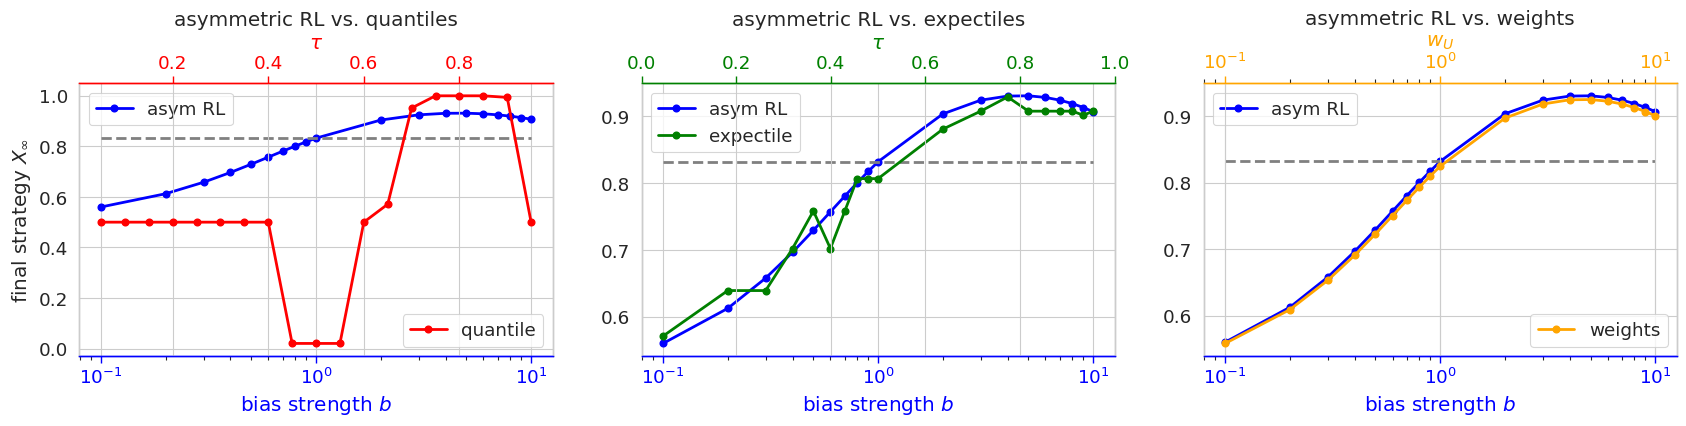

In [29]:
# Plot comparisons in poor env
plot_comparisons(b_ratios, q_list, e_list, w_list, b_xinf, 
                 q_xinf, e_xinf, w_xinf, scarcity="poor",
                 save=False, savename='_figs_v1/TwoArmedMethodComparisonPoor.png')

And now, in a rich environment:

In [30]:
# Compute comparisons in a rich environment
b_xinf, q_xinf, e_xinf, w_xinf = compute_comparisons(0.9, 0.7, b_ratios, q_list, e_list, 
                                                     w_list, gamma=0, beta=4, Rmin=-1, 
                                                     Rmax=1, nrb=29, discsig=0.05, lr=0.1)

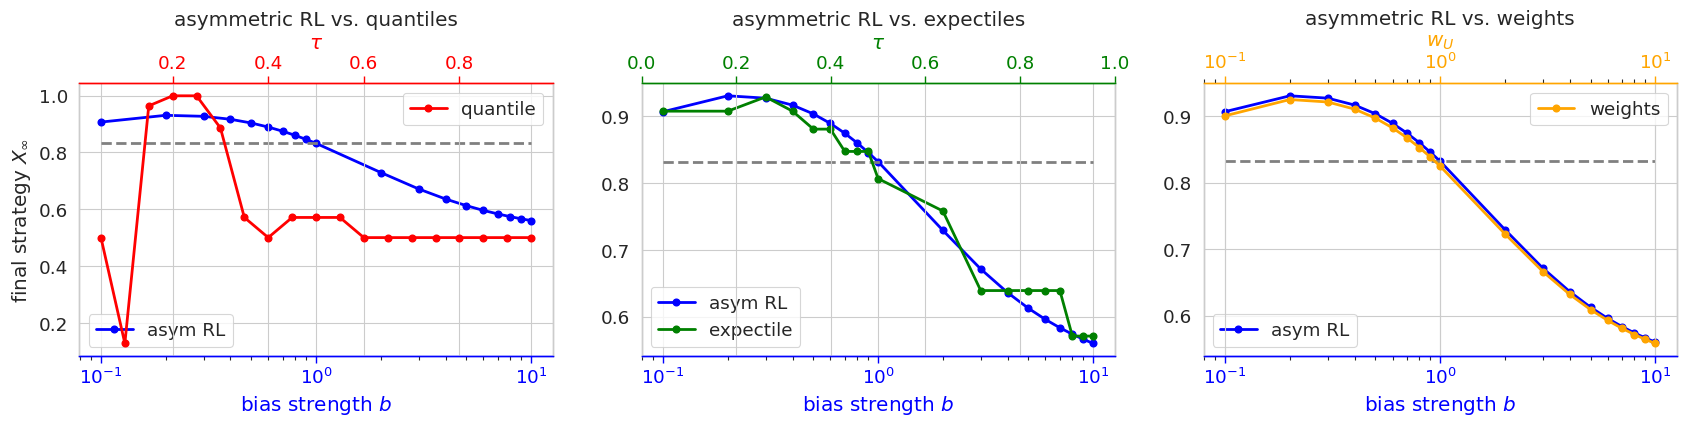

In [32]:
# Plot comparisons in a rich environment
plot_comparisons(b_ratios, q_list, e_list, w_list, b_xinf, 
                 q_xinf, e_xinf, w_xinf, scarcity="rich",
                 save=False, savename='_figs_v1/TwoArmedMethodComparisonRich.png')

### Optimism increases risk-seeking in a risk-reward dilemma

In this section, we study a risk-reward dilemma in which an agent can choose between a high-risk, high-gain option, and a low-risk, low-gain option (see Section @sec-environments). First, we define the environment:

In [33]:
# Define environment
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

#### Sanity tests

First, we carry out sanity tests in order to check that DDRLSarsa agents yield the same flow plots as a regular SARSA agent. We compare different DDRL biasing methods in order to choose the most appropriate. To this end, we first define a function that allows us to compare flowplots across 3 different conditions.

In [41]:
## Functions to plot 3 flowplots and associated trajectories

# Plot the flowplots together
def plot_3flowplots(aeis,  # list of aeis
                    x:tuple,  # which phase space axes to plot along x axes
                    y:tuple,  # which phase space axes to plot along y axes
                    NrRandom:int=4,  # number of random strategies to average over
                    Xinits=None,  # initial Xs to plot trajectories
                    decorate=False,  # whether to decorate the axes or not
                    titles=None,  # list of titles for 3 plots
                    xlabel=None,  # x-label
                    ylabel=None,  # y-label
                    cols=None,  # list of colors for trajectories
                    cmap='viridis',  # Colormap
                    axes=None,  # Axes to plot into
                    ):
    
    # Style
    sns.set_style("white")
    sns.set_context("paper", font_scale=1.25, rc={"lines.linewidth": 2})
    
    # Plot the flow plot
    for i, ax in enumerate(axes):
        aei = aeis[i]
        fp.plot_strategy_flow(aei, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                              use_RPEarrows=False, NrRandom=NrRandom, cmap=cmap, axes=ax)
        
        # Plot trajectory if initial strategies are specified
        if Xinits != None:
            trajs = []  # trajectories
            fprs = []  # are fixed points reached?
            for _, Xinit in enumerate(Xinits):
                trj, fpr = aei.trajectory(Xinit, Tmax=3000, tolerance=1e-6)
                trajs.append(trj)
                fprs.append(fpr)
                
            fp.plot_trajectories(trajs, x, y, fprs=fprs, axes=ax, cols=cols)
    
    # Add titles, xlabels and ylabels to subplots if needed
    if decorate==True:
        for i, ax in enumerate(axes): 
            ax.set_xlabel(xlabel)
            ax.set_title(titles[i])
        
        ax1.set_ylabel(ylabel)

We compare DDRLSarsa agents and regular SARSA agents across 3 values of the discount factor $\gamma$: $\gamma = 0$, $\gamma = 0.4$, and $\gamma = 0.9$. First, we create neutral DDRLSarsa agents which take the mean of their Q-value distribution as their Q-value estimate.

In [38]:
# Values of gamma
gammas = [0., 0.4, 0.9]

In [47]:
# Define agents to compare
aeis_reg = []  # regular SARSA agents
aeis_ddrl = []  # DDRLSarsa agents

for i, gamma in enumerate(gammas):
    aei_reg = stratAC(env=env, learning_rates=0.1, discount_factors=gamma, 
                      use_prefactor=True)
    aeis_reg.append(aei_reg)
    
    aei_ddrl = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                               learning_rates=0.1, discount_factors=gamma, 
                               Rmin=0, Rmax=1,
                               method="mean", use_prefactor=True)
    aeis_ddrl.append(aei_ddrl)

Now, we can visualize the flowplots.

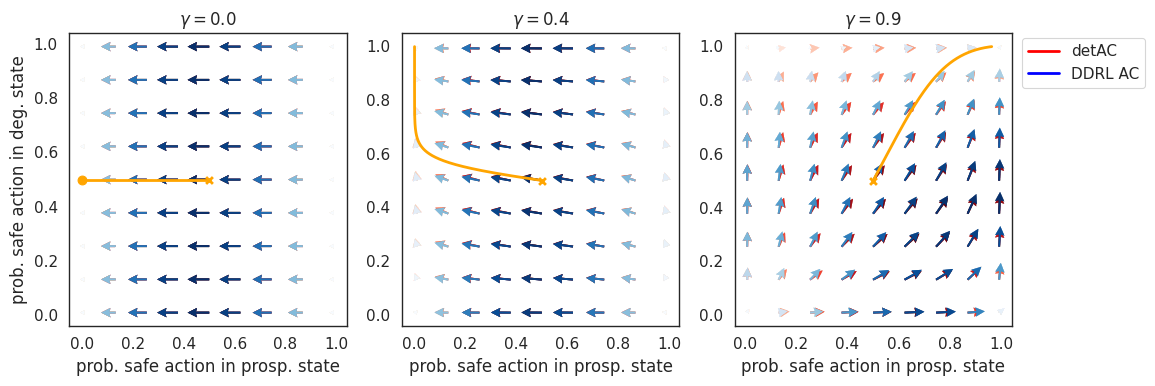

In [48]:
# Phase space items to plot along the x- and y- axes
x = ([0], [0], [0])  # prosperous state
y = ([0], [1], [0])  # degraded state

# For trajectories
Xinits = [np.ones((1, 2, 2)) * 0.5]  # initial strategy
cols = ["orange"]  # trajectory color

# Decorations
titles = [r'$\gamma = 0.0$', r'$\gamma = 0.4$', r'$\gamma = 0.9$']
xlabel = "prob. safe action in prosp. state"
ylabel = "prob. safe action in deg. state"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis_reg, x, y, NrRandom=16, cmap='Reds', axes=axes)
plot_3flowplots(aeis_ddrl, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Additional decorations
ax3.plot([], [], color='red', label='detAC')
ax3.plot([], [], color='blue', label='DDRL AC')
ax3.legend(bbox_to_anchor=(1.01, 1.01))

# Save the figure
# plt.savefig('_figs_v2/RRSanityTestMean.png', dpi=300, bbox_inches='tight')

Now, we compare the regular SARSA agents with an expectile-DDRLSarsa agent ($\tau = 0.5$, which should be equivalent with taking the mean of the Q-value distribution). Defining the expectile agents:

In [49]:
# Define agents to compare
aeis_ddrl = []  # DDRLSarsa agents

for i, gamma in enumerate(gammas):
    aei_ddrl = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.01, 
                               learning_rates=0.1, discount_factors=gamma, 
                               Rmin=0, Rmax=1,
                               method="expectile", tau=0.5, use_prefactor=True)
    aeis_ddrl.append(aei_ddrl)

And visualizing the flowplots:

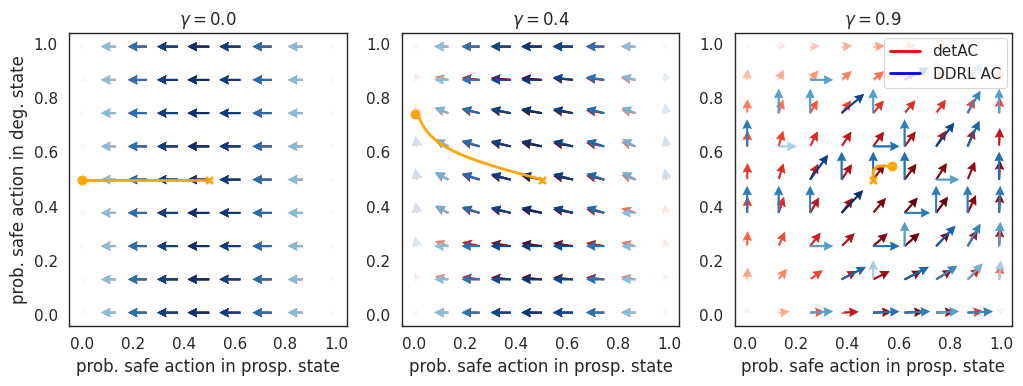

In [50]:
# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis_reg, x, y, NrRandom=16, cmap='Reds', axes=axes)
plot_3flowplots(aeis_ddrl, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Additional decorations
ax3.plot([], [], color='red', label='detAC')
ax3.plot([], [], color='blue', label='DDRL AC')
ax3.legend(bbox_to_anchor=(1.01, 1.01))

# Save the figure
# plt.savefig('_figs_v2/RRSanityTestExpectile.png', dpi=300, bbox_inches='tight')

Finally, we compare the regular SARSA agents with a weights-DDRLSarsa agent ($w_U = 1$, which should be equivalent with taking the mean of the Q-value distribution). Defining the weights agents:

In [54]:
# Define agents to compare
aeis_ddrl = []  # DDRLSarsa agents

for i, gamma in enumerate(gammas):
    aei_ddrl = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                               learning_rates=0.1, discount_factors=gamma, 
                               Rmin=0, Rmax=1,
                               method="weights", wU=1., use_prefactor=True)
    aeis_ddrl.append(aei_ddrl)

Now visualizing:

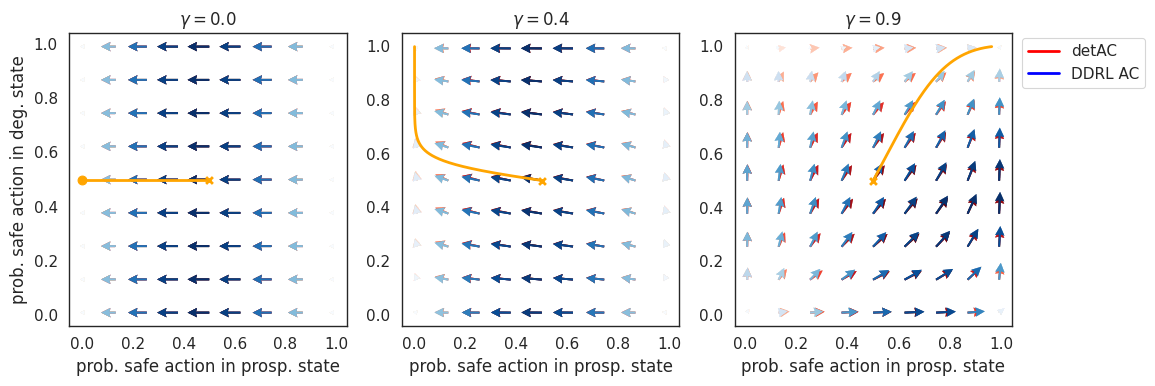

In [55]:
# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis_reg, x, y, NrRandom=16, cmap='Reds', axes=axes)
plot_3flowplots(aeis_ddrl, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Additional decorations
ax3.plot([], [], color='red', label='detAC')
ax3.plot([], [], color='blue', label='DDRL AC')
ax3.legend(bbox_to_anchor=(1.01, 1.01))

# Save the figure
# plt.savefig('_figs_v2/RRSanityTestWeights.png', dpi=300, bbox_inches='tight')

#### Influence of optimism/pessimism

Since the flowplots obtained with the weights method are closest to the regular SARSA agents' flowplots, we use this method to implement optimism/pessimism. We study the influence of optimism for a low discount factor $\gamma = 0.4$, and for a high discount factor $\gamma = 0.9$. We assume that, in the degraded state, the agent always chooses the safe action (since it is the only one which can take it back to the prosperous state).

In [56]:
# Levels of optimism/pessimism (defined by upper weight values w_U)
weights = np.array([0.1, 0.2, 0.4, 0.8, 1., 2., 4., 8., 10.])

# Phase space items to plot along the x-axis
x = ([0], [0], [0]) 

# Range and resolution
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

# Value of X^{0,1,0}
otherXs = np.ones((len(res)))

For a low discount factor $\gamma = 0.4$:

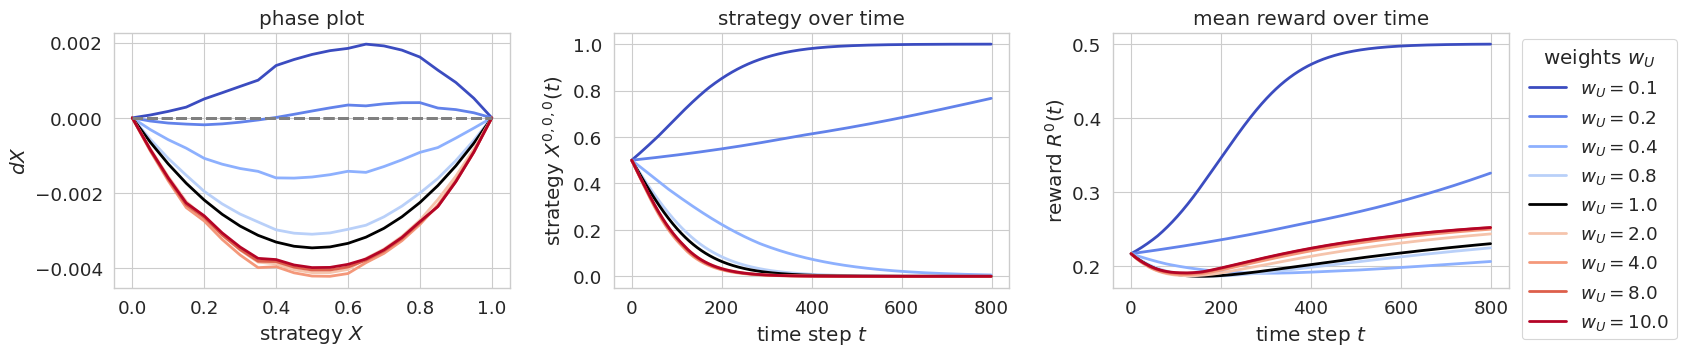

In [66]:
# Plot and save - gamma = 0.4
compare_levels(env, weights, gamma=0.4, beta=50, Rmin=0, Rmax=1, xinds=x, 
               res=res, algo='AC', nrb=29, discsig=0.05, 
               traj_len=800, otherXs=otherXs, cmap='coolwarm', 
               save=False, savename='_figs_v2/RRPhasePlotGamma04.png')

For a high discount factor $\gamma=0.9$:

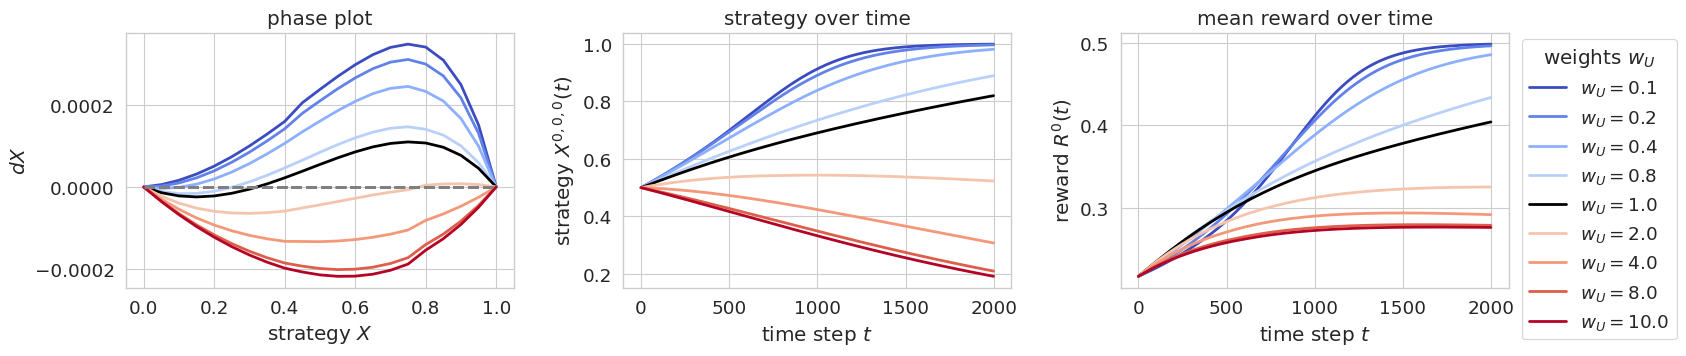

In [69]:
# Plot and save - gamma = 0.9
compare_levels(env, weights, gamma=0.9, beta=50., Rmin=0, Rmax=1, 
               xinds=x, algo='AC', res=res, nrb=29, discsig=0.05, 
               traj_len=2000, otherXs=otherXs, cmap='coolwarm', 
               save=False, savename='_figs_v2/RRPhasePlotGamma09.png')

We can visualize the impact of optimism/pessimism on the agent's strategy in both states, by using flowplots. Here, we show flowplots for a pessimistic agent ($w_U = 0.2$), a neutral agent ($w_U = 1$), and an optimistic agent ($w_U = 5$). First, we study how optimism/pessimism impacts the strategy of an agent with low discount factor $\gamma = 0.4$.

In [70]:
x = ([0], [0], [0])  # prosperous state
y = ([0], [1], [0])  # degraded state
w_list = [0.2, 1, 5]  # list of weights

In [76]:
# Define agents to compare
aeis = [] # DDRLActorCritic agents

for i, w in enumerate(w_list):
    aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                          learning_rates=0.1, discount_factors=0.4, 
                          Rmin=0, Rmax=1,
                          method="weights", wU=w, use_prefactor=True)
    aeis.append(aei)

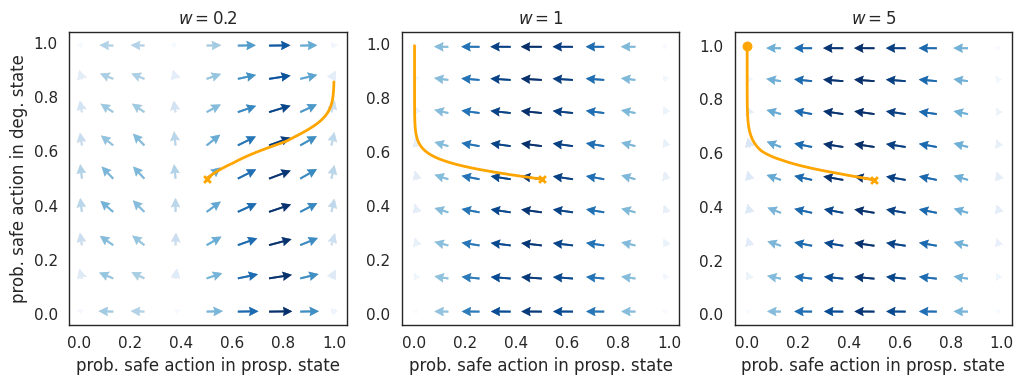

In [77]:
# For trajectories
Xinits = [np.ones((1, 2, 2)) * 0.5]  # initial strategy
cols = ["orange"]  # trajectory color

# Decorations
titles = [r'$w = 0.2$', r'$w = 1$', r'$w = 5$']
xlabel = "prob. safe action in prosp. state"
ylabel = "prob. safe action in deg. state"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Visualize fixed point coordinates
for i, aei in enumerate(aeis):
    ax = axes[i]
    trj, fpr = aei.trajectory(Xinits[0], Tmax=3000, tolerance=1e-6)
    fixedp = trj[-1, 0, :, 0]
    fx = fixedp[0]
    fy = fixedp[1]

# Save the figure
# plt.savefig('_figs_v2/RRFlowplotsGamma04Beta50.png', dpi=300, bbox_inches='tight')

We then turn to agents with a high discount factor $\gamma=0.9$.

In [78]:
# Define agents to compare
aeis = [] # DDRLActorCritic agents

for i, w in enumerate(w_list):
    aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                          learning_rates=0.1, discount_factors=0.9, 
                          Rmin=0, Rmax=1,
                          method="weights", wU=w, use_prefactor=True)
    aeis.append(aei)

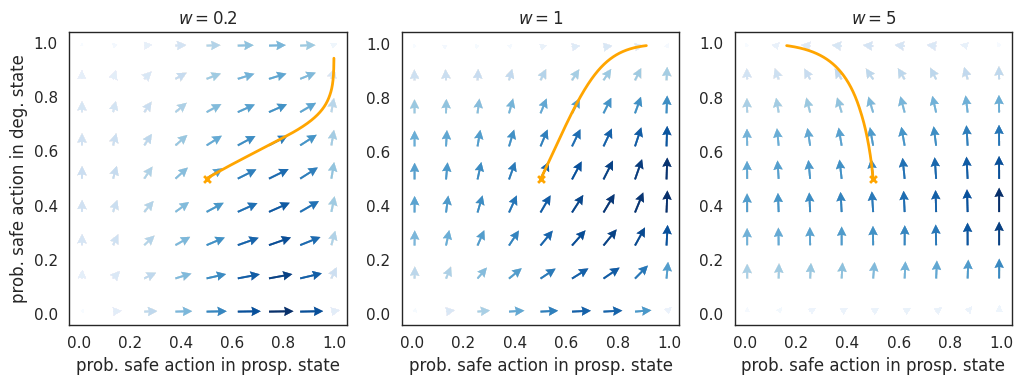

In [79]:
# For trajectories
Xinits = [np.ones((1, 2, 2)) * 0.5]  # initial strategy
cols = ["orange"]  # trajectory color

# Decorations
titles = [r'$w = 0.2$', r'$w = 1$', r'$w = 5$']
xlabel = "prob. safe action in prosp. state"
ylabel = "prob. safe action in deg. state"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Visualize fixed point coordinates
for i, aei in enumerate(aeis):
    ax = axes[i]
    trj, fpr = aei.trajectory(Xinits[0], Tmax=3000, tolerance=1e-6)
    fixedp = trj[-1, 0, :, 0]
    fx = fixedp[0]
    fy = fixedp[1]

# Save the figure
# plt.savefig('_figs_v2/RRFlowplotsGamma09Beta50.png', dpi=300, bbox_inches='tight')

### Optimism enhances cooperation in a stag-hunt game

In this section, we investigate the impact of optimism/pessimism on the stag-hunt game defined in Section @sec-environments. This is a coordination game between two agents: if both agents cooperate at the same time, they reap the most rewards. First, we define the environment:

In [80]:
env = SocialDilemma(R=3, P=0, S=-2, T=1)

#### Sanity tests

As above, we carry out sanity tests in order to check that the behavior of neutral DDRLSarsa agents imitate the behavior of regular SARSA agents. Once again, we compare the "mean", "expectile", and "weights" methods. 

In [81]:
# Methods
methods = ["mean", "expectile", "weights"]

In [82]:
# Define agents to compare
aeis_ddrl = [] # DDRLSarsa agents
aeis_reg = []  # regular SARSA agents

for i, method in enumerate(methods):
    aei_ddrl = DDRLSarsa(env, nr_reward_bins=29, discretization_sigma=0.05, 
                        learning_rates=0.1, discount_factors=0.9, 
                        choice_intensities=50, Rmin=-2, Rmax=3,
                        method=method, use_prefactor=True)
    aeis_ddrl.append(aei_ddrl)
    
    aei_reg = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, 
                         choice_intensities=50, use_prefactor=True)
    aeis_reg.append(aei_reg)

Additionally, we plot trajectories with various initial conditions for better visualization.

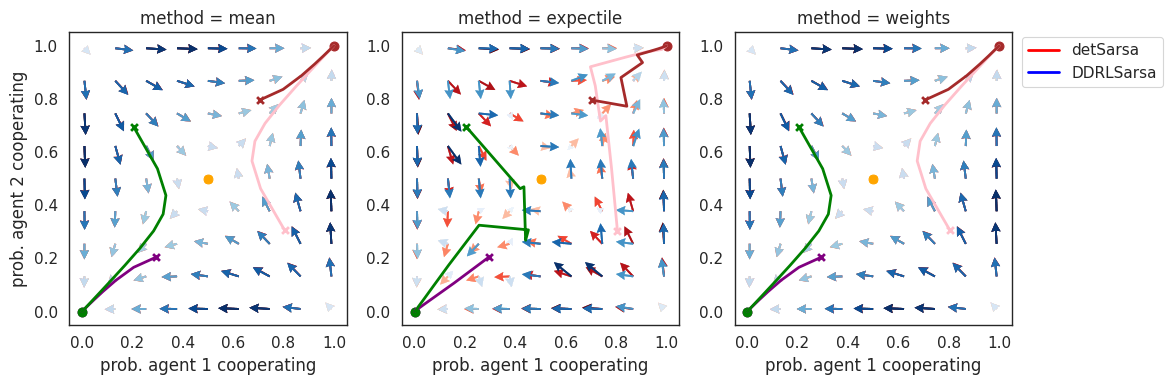

In [83]:
# Phase space items to plot along the axes
x = ([0], [0], [0])  # agent 1
y = ([1], [0], [0])  # agent 2

# For trajectories
Xinits = []
xys = [(0.5, 0.5), (0.295, 0.205), (0.205, 0.695), (0.805, 0.305), (0.705, 0.795)]
cols = ['orange', 'purple', 'green', 'pink', 'brown']
        
for t, xy in enumerate(xys):
    Xinit = np.ones((2, 1, 2)) * 0.5
    Xinit[0, 0, 0] = xy[0]
    Xinit[1, 0, 0] = xy[1]
    Xinit[0, 0, 1] = 1 - Xinit[0, 0, 0]
    Xinit[1, 0, 1] = 1 - Xinit[1, 0, 0]
    Xinits.append(Xinit)

# Decorations
titles = ["method = mean", "method = expectile", "method = weights"]
xlabel = "prob. agent 1 cooperating"
ylabel = "prob. agent 2 cooperating"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis_reg, x, y, NrRandom=16, cmap='Reds', axes=axes)
plot_3flowplots(aeis_ddrl, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Additional decorations
ax3.plot([], [], color='red', label='detSarsa')
ax3.plot([], [], color='blue', label='DDRLSarsa')
ax3.legend(bbox_to_anchor=(1.01, 1.01))

# Save the figure
# plt.savefig('_figs_v2/SHSanityTests.png', dpi=300, bbox_inches='tight')

#### Influence of optimism/pessimism

Once again, neutral weights-DDRLSarsa agents show less errors than neutral expectile-DDRLSarsa agents. Therefore, we use the weights method to explore the effects of optimism and pessimism on cooperation in the stag-hunt game. In particular, we look at how optimism/pessimism impacts the separatrix of the flowplot. This separatrix demarcates the domain where all initial strategies lead to mutual cooperation from the domain where all initial strategies lead to mutual defection. 

First, let's define functions to plot this separatrix.

In [84]:
def compile_strategy(p0c:float,  # cooperation probability of agent zero
                     p1c:float):  # cooperation probability of agent one
    strat = np.zeros((2, 1, 2))
    strat[0, 0, 0] = p0c
    strat[1, 0, 0] = p1c
    strat[0, 0, 1] = 1 - p0c
    strat[1, 0, 1] = 1 - p1c
    return strat                         

def plot_separatrix(aei, ax):    
    # Add saddle node
    # by reversing the dynamics from two agents with identical strategies
    o = [0.5, 0.5]; o = compile_strategy(*o)
    for _ in range(1000): o, _ = aei.reverse_step(o)
    # Add separatrix
    o = o[:, 0, 0] - np.array([0, 0.0001])
    o1 = compile_strategy(*o)
    o2 = compile_strategy(*o[::-1])
    sep1=[]; sep2=[]
    for _ in range(1000): o1, _ = aei.reverse_step(o1); sep1.append(o1)
    for _ in range(1000): o2, _ = aei.reverse_step(o2); sep2.append(o2)
    fp.plot_trajectories([sep1, sep2], x=x, y=y, cols=['dimgray'], lws=[1],
                         lss=['--'], alphas=[0.95], axes=ax)

We compare a pessimistic agent with $w_U=0.25$, with a neutral agent ($w_U=1$) and an optimistic agent ($w_U = 4$).

In [85]:
weights = [0.25, 1., 4.]

In [86]:
# Define agents to compare
aeis = [] # DDRLSarsa agents

for i, weight in enumerate(weights):
    aei = DDRLSarsa(env, nr_reward_bins=29, discretization_sigma=0.05, 
                    learning_rates=0.1, discount_factors=0.9, 
                    choice_intensities=50, Rmin=-2, Rmax=3,
                    method="weights", wU=weight, use_prefactor=True)
    aeis.append(aei)

Now plotting:

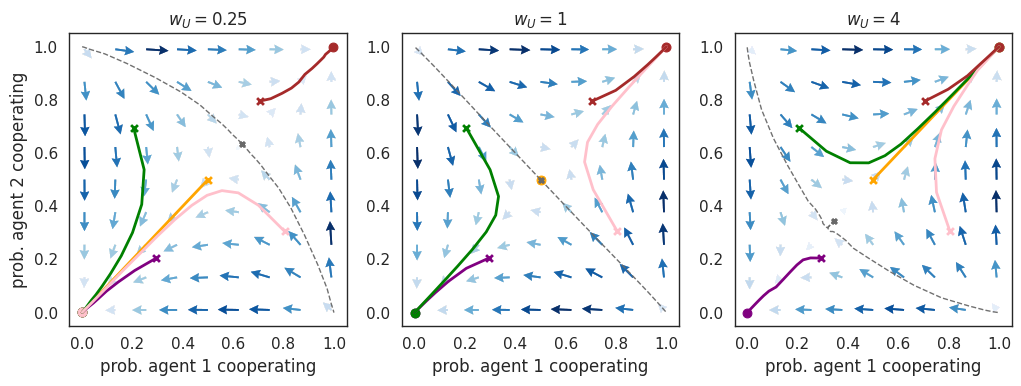

In [87]:
# Decorations
titles = [r'$w_U=0.25$', r'$w_U=1$', r'$w_U=4$']
xlabel = "prob. agent 1 cooperating"
ylabel = "prob. agent 2 cooperating"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Plot separatrices
for i, aei in enumerate(aeis):
    ax = axes[i]
    plot_separatrix(aei, ax)

# Save the figure
# plt.savefig('_figs_v2/SHFlowPlots.png', dpi=300, bbox_inches='tight')

We can also plot the phase plot for one agent, assuming the other agent always plays the same strategy as the first one. This is equivalent with visualizing the diagonal of the above flowplots. 

In [88]:
weights = np.array([0.1, 0.2, 0.4, 0.8, 1., 2., 4., 8., 10.])

x = ([0], [0], [0]) 
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999
otherXs = np.linspace(0, 1., 21)
otherXs[0] = 0.0001
otherXs[-1] = 0.9999

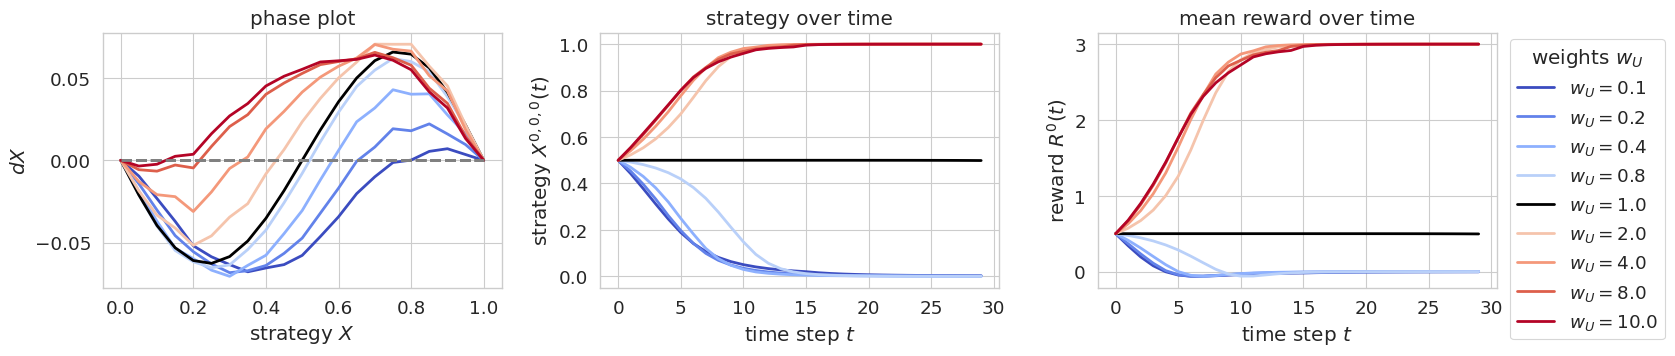

In [89]:
compare_levels(env, weights, gamma=0.9, beta=50., Rmin=-2, Rmax=3, 
               xinds=x, res=res, nrb=29, discsig=0.05, traj_len=30, 
               otherXs=otherXs, cmap='coolwarm', save=False, 
               savename='_figs_v2/SHPhasePlots.png')

### Optimism has no effect in a prisoner's dilemma

As a complement, we can turn the stag-hunt game into a prisoner's dilemma, which is another social dilemma with a different reward structure. In a prisoner's dilemma, typically, mutual cooperation is not an equilibrium; both agents are incentivized to defect. First, we define the environment:

In [90]:
env = SocialDilemma(R=1, P=0, S=-2, T=3)

And we carry the same sanity tests as above:

In [91]:
methods = ["mean", "expectile", "weights"]

In [92]:
# Define agents to compare
aeis_ddrl = [] # DDRLSarsa agents
aeis_reg = []  # regular SARSA agents

for i, method in enumerate(methods):
    aei_ddrl = DDRLSarsa(env, nr_reward_bins=29, discretization_sigma=0.05, 
                         learning_rates=0.1, discount_factors=0.9, 
                         choice_intensities=50, Rmin=-2, Rmax=3,
                         method=method, use_prefactor=True)
    aeis_ddrl.append(aei_ddrl)
    
    aei_reg = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, 
                         choice_intensities=50, use_prefactor=True)
    aeis_reg.append(aei_reg)

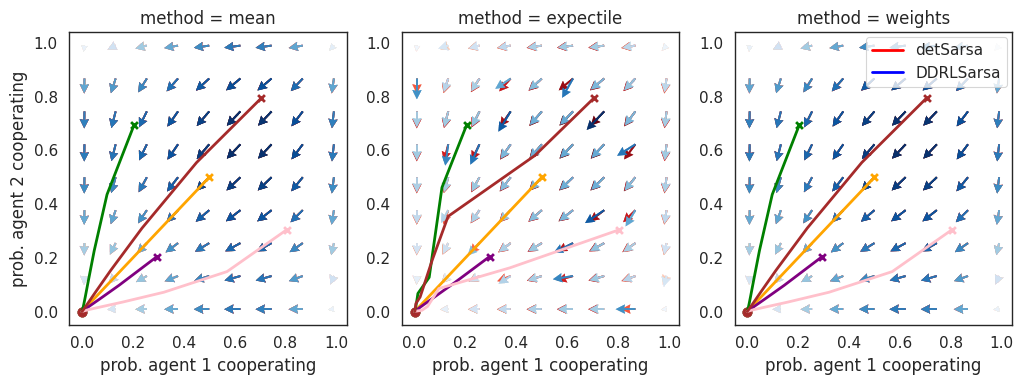

In [97]:
# Phase space items to plot on axes
x = ([0], [0], [0])  # agent 1
y = ([1], [0], [0])  # agent 2

# For trajectories
Xinits = []
xys = [(0.5, 0.5), (0.295, 0.205), (0.205, 0.695), (0.805, 0.305), (0.705, 0.795)]
cols = ['orange', 'purple', 'green', 'pink', 'brown']
        
for t, xy in enumerate(xys):
    Xinit = np.ones((2, 1, 2)) * 0.5
    Xinit[0, 0, 0] = xy[0]
    Xinit[1, 0, 0] = xy[1]
    Xinit[0, 0, 1] = 1 - Xinit[0, 0, 0]
    Xinit[1, 0, 1] = 1 - Xinit[1, 0, 0]
    Xinits.append(Xinit)

# Decorations
titles = ["method = mean", "method = expectile", "method = weights"]
xlabel = "prob. agent 1 cooperating"
ylabel = "prob. agent 2 cooperating"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis_reg, x, y, NrRandom=16, cmap='Reds', axes=axes)
plot_3flowplots(aeis_ddrl, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Additional decorations
ax3.plot([], [], color='red', label='detSarsa')
ax3.plot([], [], color='blue', label='DDRLSarsa')
ax3.legend(bbox_to_anchor=(1.01, 1.01))

# Save the figure
# plt.savefig('_figs_v2/PDSanityTests.png', dpi=300, bbox_inches='tight')

We can investigate the influence of optimism or pessimism by plotting the same phase plots and strategy plots as above, assuming the second agent always behaves like the first. 

In [94]:
weights = np.array([0.1, 0.2, 0.4, 0.8, 1., 2., 4., 8., 10.])

x = ([0], [0], [0]) 
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999
otherXs = np.linspace(0, 1., 21)
otherXs[0] = 0.0001
otherXs[-1] = 0.9999

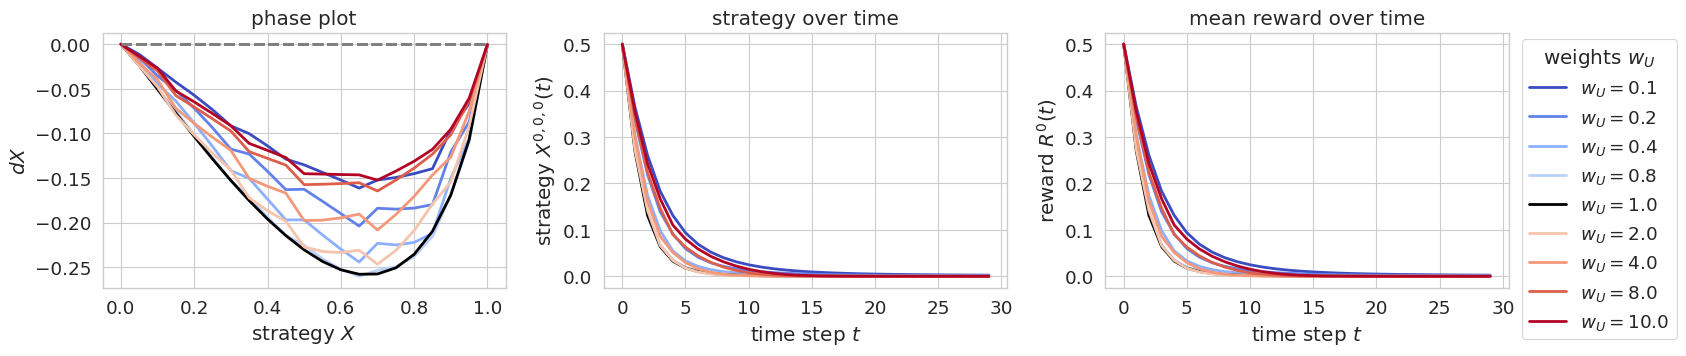

In [95]:
compare_levels(env, weights, gamma=0.9, beta=50., Rmin=-2, Rmax=3, 
               xinds=x, res=res, nrb=29, discsig=0.05, traj_len=30, 
               otherXs=otherXs, cmap='coolwarm', save=False, 
               savename='_figs_v2/PDPhasePlots.png')